In [1]:
CUDA_VISIBLE_DEVICES=4
import numpy as np
import matplotlib.pyplot as plt
import os
plt.style.use("default")
import re

In [2]:
# Define the absolute paths to the results files
EXPERIMENT_DIR_INDIV = "../../../experiments/cost_fixed/"
EXPERIMENT_DIR_JOINT = "../../../experiments/cost_semivariable/"

#METRICS = ['cityblock', 'euclidean', 'sqeuclidean', 'minkowski', 'chebyshev', 'canberra']
METRICS = ['sqeuclidean']


METRIC_LABELS = {
    'cityblock':   r'$L_1$',
    'euclidean':   r'$L_2$',
    'sqeuclidean': r'Test set / OOD over $L_2^2$',
    'minkowski':   r'$L_3$',
    'chebyshev':   r'$L_\infty$',
    'canberra':    r'Canberra',
}

# Model directory templates
MODEL_INDIV_TEMPLATE = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_{}"
MODEL_JOINT_NAME     = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean"

In [3]:
def load_results(path_tot, path_not):
    if not os.path.exists(path_tot):
        print(f"Error: File not found: {path_tot}")
        return None, None
    if not os.path.exists(path_not):
        print(f"Error: File not found: {path_not}")
        return None, None
        
    print(f"Loading {path_tot}...")
    data_tot = np.load(path_tot, allow_pickle=True)
    print(f"Loading {path_not}...")
    data_not = np.load(path_not, allow_pickle=True)
    
    return data_tot, data_not

def extract_metrics(data_array):
    if data_array is None: return {}
    
    metrics = {
        'MAE': [],
        'MAPE': [],
        'Hellinger': [],
        'OT Cost Diff': [],
        'Total Variation': [],
        'Run Time (Seconds)': []
    }
    
    for item in data_array:
        # Dictionary keys from run_inference.py
        if 'mae_sparse' in item: metrics['MAE'].append(item['mae_sparse'])
        if 'mape_sparse' in item: metrics['MAPE'].append(item['mape_sparse'])
        if 'hellinger_sparse' in item: metrics['Hellinger'].append(item['hellinger_sparse'])
        if 'otcost_diff' in item: metrics['OT Cost Diff'].append(item['otcost_diff'])
        if 'tv_sparse' in item: metrics['Total Variation'].append(item['tv_sparse'])
        if 'run_time' in item: metrics['Run Time (Seconds)'].append(item['run_time'])
            
    return metrics

Loading data for metric: sqeuclidean...
Loading data for metric: sqeuclidean, from path: ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_tot.npy
Loading data for metric: sqeuclidean, from path: ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_not.npy
Loading ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_tot.npy...
Loading ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_c

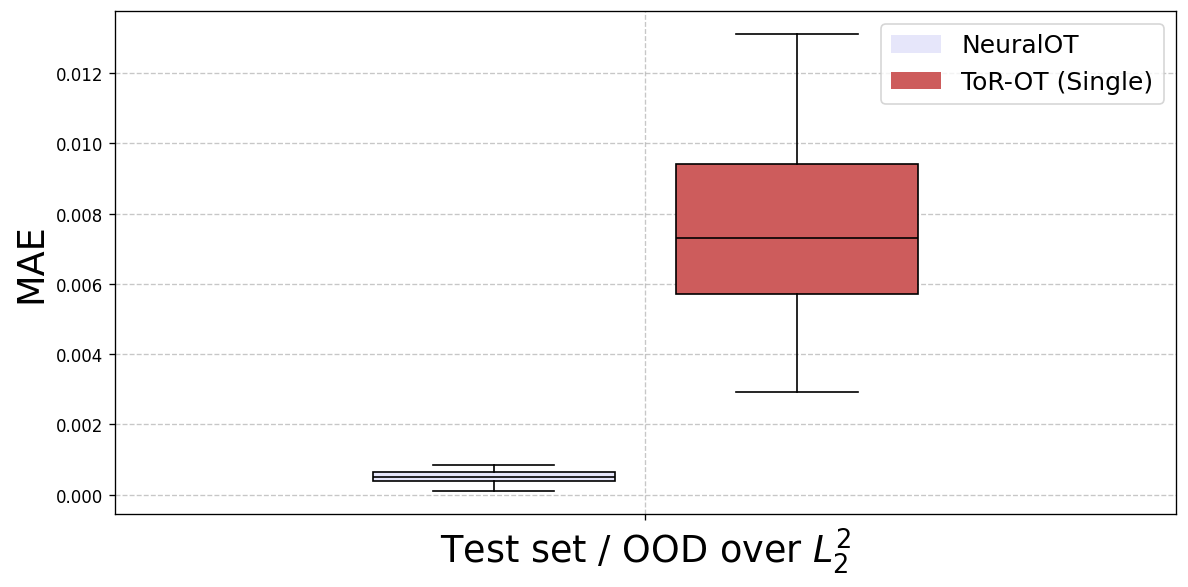

Generating plot for MAPE...
Saved: img/2d_ood_mape.png


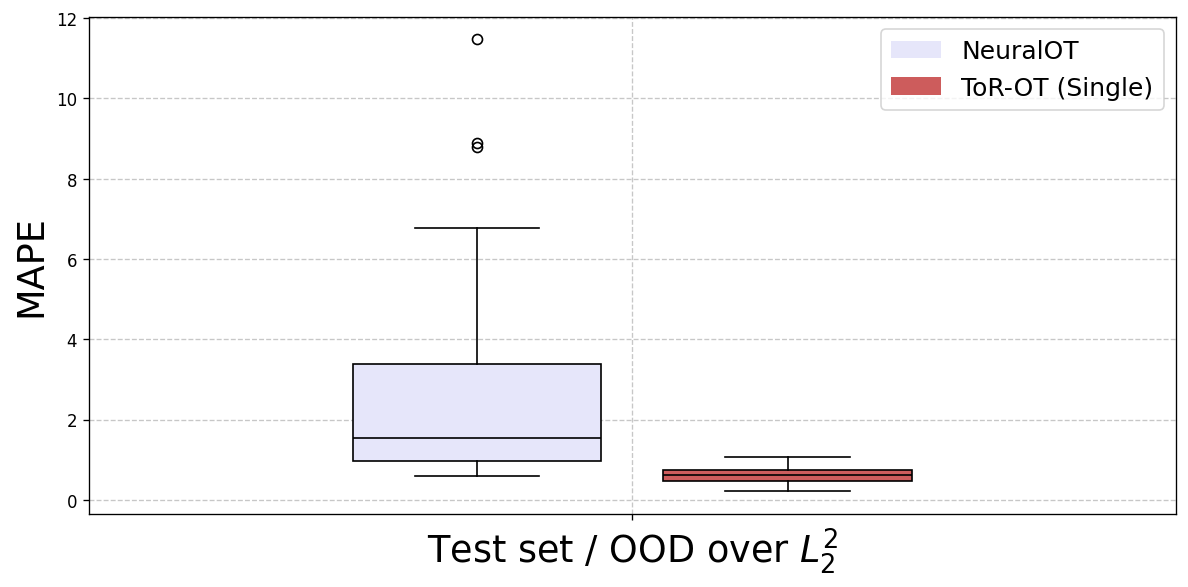

Generating plot for Hellinger...


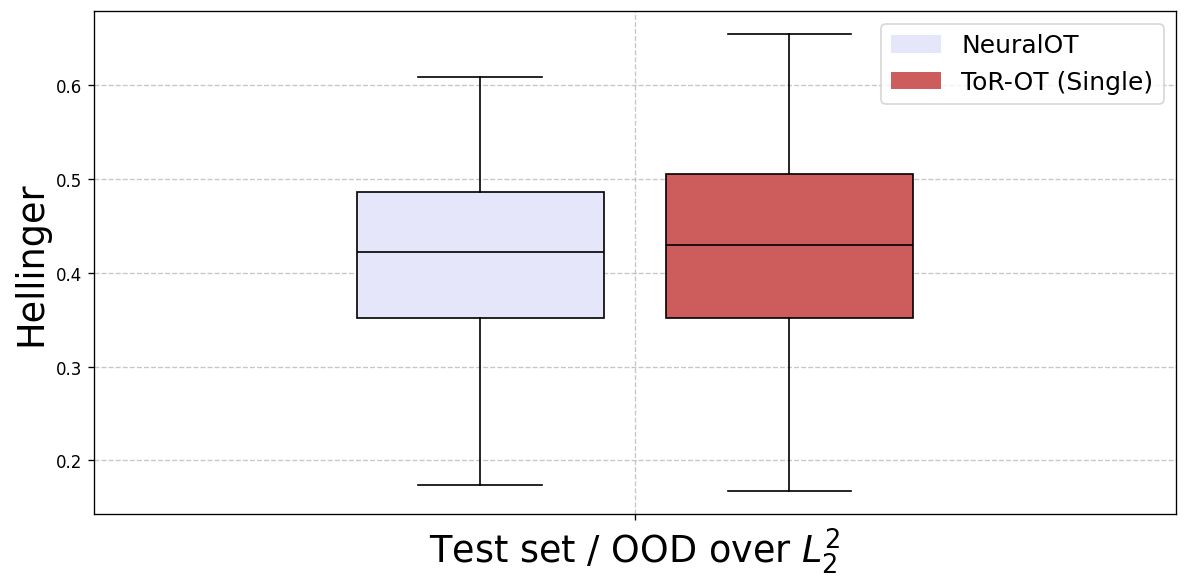

Generating plot for OT Cost Diff...


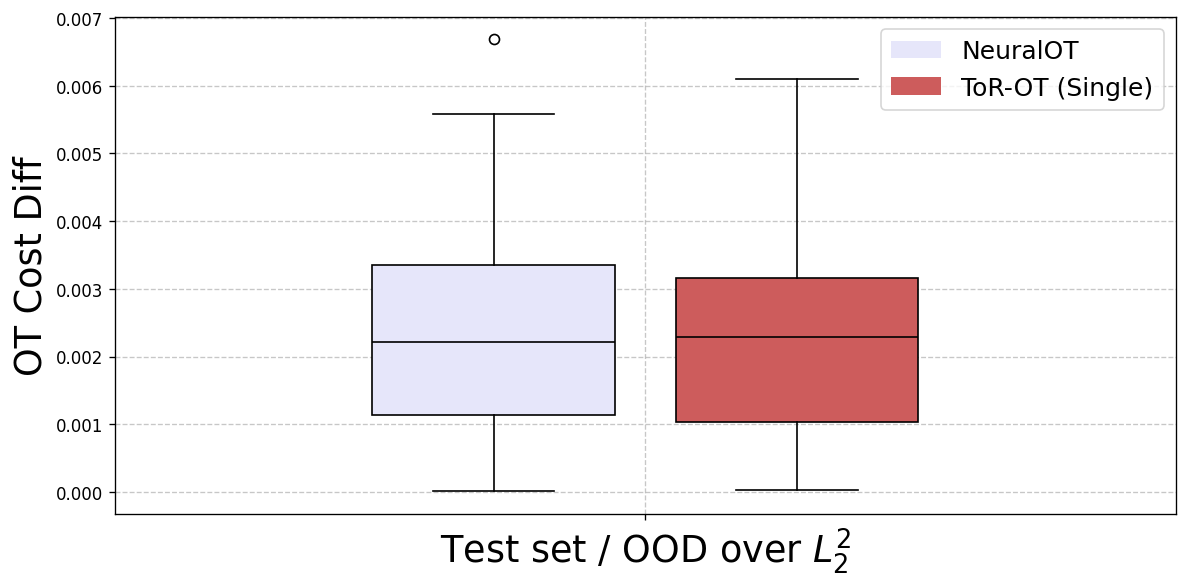

Generating plot for Total Variation...


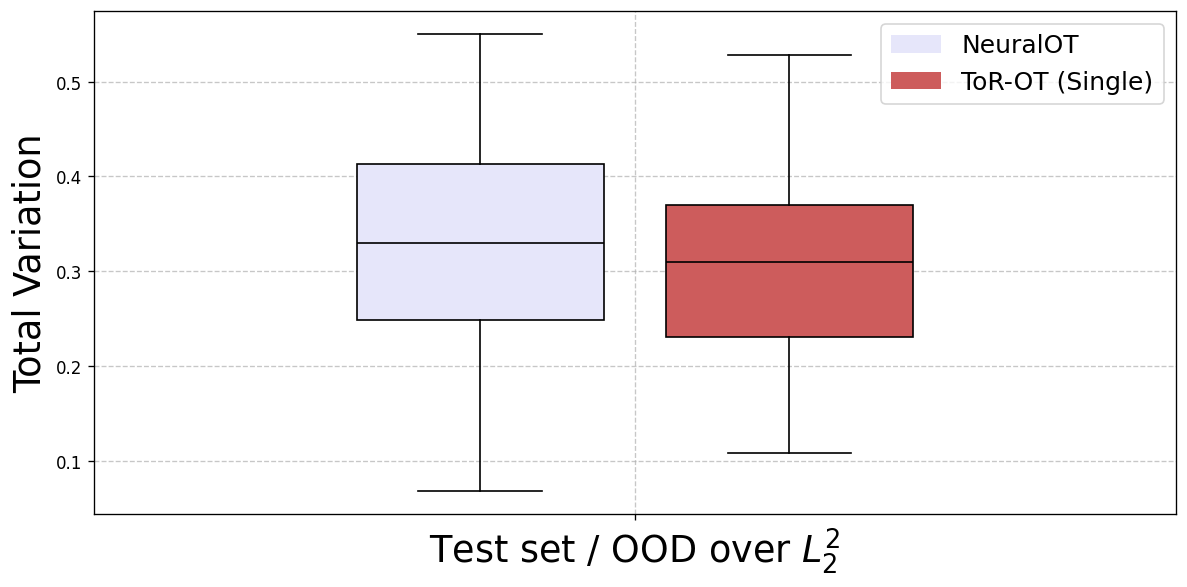

Generating plot for Run Time (Seconds)...
Saved: img/2d_ood_run_time_seconds.png


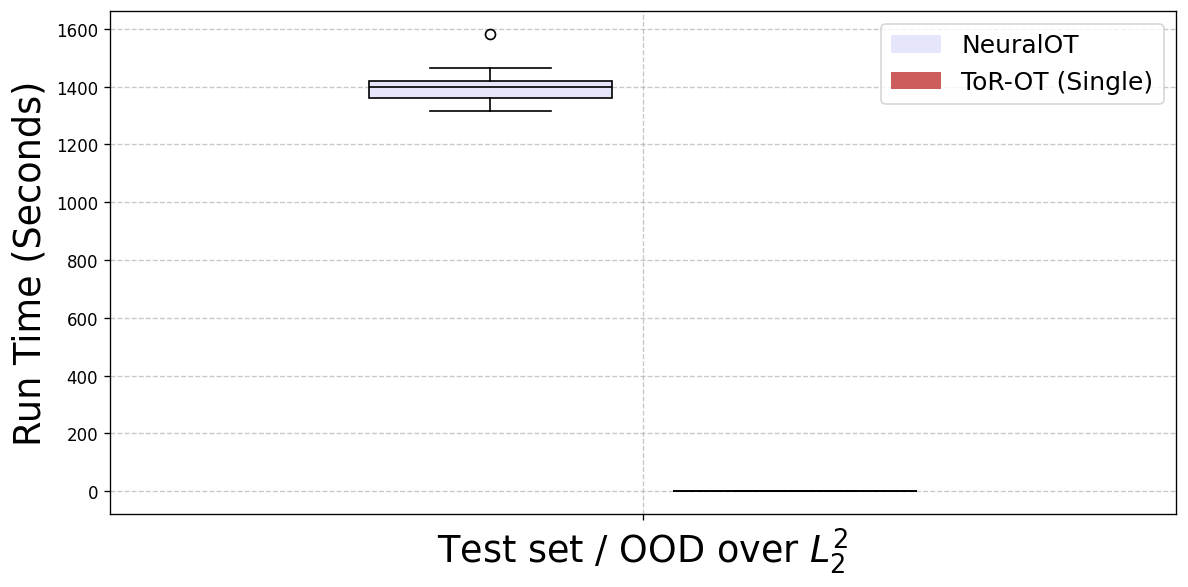

In [4]:
PERFORMANCE_METRICS = ['MAE', 'MAPE', 'Hellinger', 'OT Cost Diff', 'Total Variation', 'Run Time (Seconds)']

# Initialize data structure to hold results for all metrics
# Structure: { metric_name: { 'TOT_INDIV': ..., 'NOT_INDIV': ..., 'TOT_JOINT': ... } }
all_results_data = {}

# --- Step 1: Load ALL Data ---
for metric in METRICS:
    print(f"Loading data for metric: {metric}...")
    
    # Dynamic paths for INDIV experiments
    model_dir_indiv = MODEL_INDIV_TEMPLATE.format(metric)
    path_indiv_tot = os.path.join(EXPERIMENT_DIR_INDIV, model_dir_indiv, f"eval_all_pairs_2d_{metric}_results_tot.npy")
    path_indiv_not = os.path.join(EXPERIMENT_DIR_INDIV, model_dir_indiv, f"eval_all_pairs_2d_{metric}_results_not.npy")
    print(f"Loading data for metric: {metric}, from path: {path_indiv_tot}")
    print(f"Loading data for metric: {metric}, from path: {path_indiv_not}")
    
    # Dynamic paths for JOINT experiments
    # Note: MODEL_JOINT_NAME is constant, but filename depends on metric
    
    #path_joint_tot = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_JOINT_NAME, f"eval_all_pairs_2d_{metric}_results_tot.npy")
    path_joint_not = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_JOINT_NAME, f"eval_all_pairs_2d_{metric}_results_not.npy")
    
    data_indiv_tot, data_indiv_not = load_results(path_indiv_tot, path_indiv_not)
    #data_joint_tot, _ = load_results(path_joint_tot, path_joint_not) # We ignore data_joint_not
    
    if data_indiv_tot is None: # or data_joint_tot is None:
        print(f"Skipping {metric} due to missing data.")
        continue
        
    all_results_data[metric] = {
        'NOT_INDIV': extract_metrics(data_indiv_not),
        'TOT_INDIV': extract_metrics(data_indiv_tot),
        #'TOT_JOINT': extract_metrics(data_joint_tot),
        # 'NOT_JOINT' excluded
    }

# --- Step 2: Generate Plots by Performance Metric ---

# Data Keys used to access the dictionary
DATA_KEYS = ['NOT_INDIV', 'TOT_INDIV']#, 'TOT_JOINT']

# Mapping from Data Keys to Display Labels
LABEL_MAPPING = {
    'NOT_INDIV': 'NeuralOT',
    'TOT_INDIV': 'ToR-OT (Single)',
    #'TOT_JOINT': 'ToR-OT (Joint)'
}

COLORS = ['lavender', 'indianred', 'lightgreen']

for perf_metric in PERFORMANCE_METRICS:
    print(f"Generating plot for {perf_metric}...")
    
    # Prepare data for plotting
    plot_data = []
    valid_metrics = [] # To keep track of which distance metrics we actually have data for
    
    for dist_metric in METRICS:
        if dist_metric in all_results_data:
            valid_metrics.append(dist_metric)
            metric_data = all_results_data[dist_metric]
            
            # Append data in the order of DATA_KEYS
            for key in DATA_KEYS:
                # The extract_metrics returns a dict like {'MAE': [...], ...}
                values = metric_data[key].get(perf_metric, [])
                plot_data.append(values)
    
    if not plot_data:
        print(f"No data found to plot for {perf_metric}")
        continue

    fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
    
    # Position calculations
    num_distance_metrics = len(valid_metrics)
    num_bars_per_group = len(DATA_KEYS)
    group_width = 0.8
    bar_width = group_width / num_bars_per_group
    
    # Calculate positions for all boxplots
    positions = []
    for i in range(num_distance_metrics):
        center = i + 1
        # Offsets calculation centered around the group
        start_offset = -(num_bars_per_group - 1) * bar_width / 2.0
        for j in range(num_bars_per_group):
            offset = start_offset + (j * bar_width)
            positions.append(center + offset)
            
    # Create boxplots
    bp = ax.boxplot(plot_data, positions=positions, widths=bar_width*0.8, patch_artist=True, medianprops=dict(color="black"))
    
    # Color the boxplots
    for i, patch in enumerate(bp['boxes']):
        # Cycle through the colors
        color_idx = i % num_bars_per_group
        patch.set_facecolor(COLORS[color_idx])
        
    # Set X-axis labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    # Use mapped labels for X-axis
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)
    
    #ax.set_title(f'OOD comparison: {perf_metric} across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)
    
    # Custom Legend using Mapped Labels
    from matplotlib.patches import Patch
    # Use DATA_KEYS order to get colors and map to labels
    legend_elements = [
        Patch(facecolor=COLORS[i], label=LABEL_MAPPING[DATA_KEYS[i]]) 
        for i in range(len(DATA_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=15)
    
    plt.tight_layout()
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/2d_ood_{safe_metric}.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    
    plt.show()


TEST SET ANALYSIS
Trying metric:  sqeuclidean
Loading:  ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_sqeuclidean/eval_all_testset_2d_sqeuclidean_results_tot.npy
Data:  {'source': 'Batch_0', 'target': 'Batch_0', 'otcost_diff': 0.0020644469186663628, 'mae_sparse': np.float64(0.006155689297146192), 'mape_sparse': 0.4986108330538555, 'hellinger_sparse': 0.34136797249297063, 'tv_sparse': 0.24930541653442076, 'run_time': 1.1446690559387207}
Data type:  <class 'numpy.ndarray'>
Data[0] type:  <class 'dict'>
Data shape:  (1000,)
Loaded:  {'MAE': array([0.00615569, 0.00454866, 0.00573651, 0.00522636, 0.00429254,
       0.00493098, 0.00562216, 0.00579468, 0.00549838, 0.00500209,
       0.00614104, 0.0053484 , 0.00495296, 0.00527145, 0.00631155,
       0.00531302, 0.00765232, 0.00527488, 0.00509997, 0.00706842,
       0.00546847, 0.00539141, 0.00481134, 0.00738763

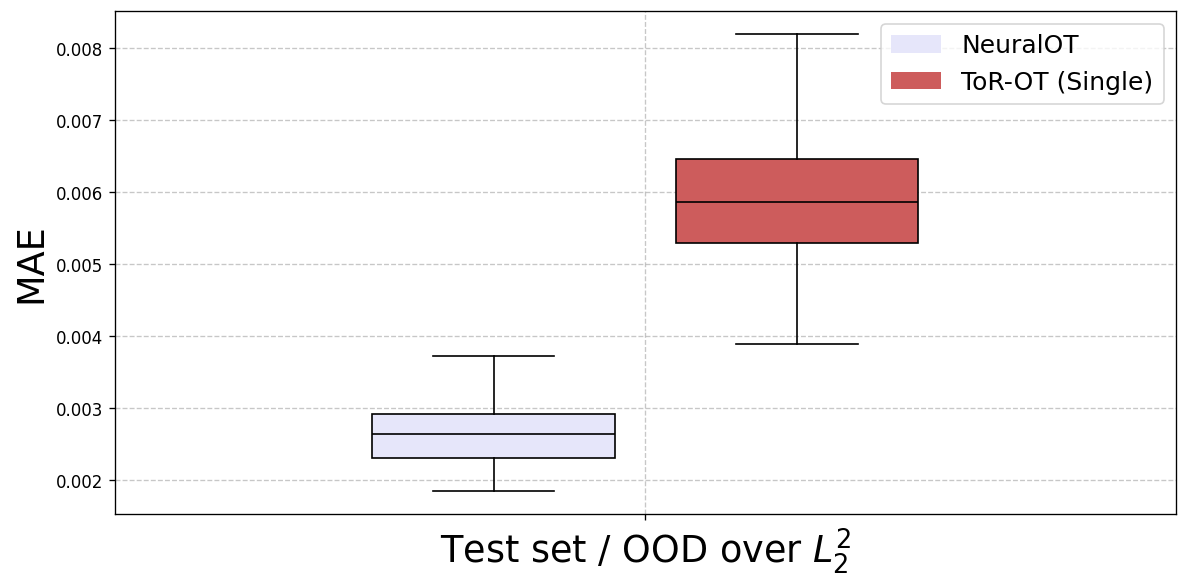

Generating Test Set Plot for MAPE...
Saved: img/2d_testset_mape.png


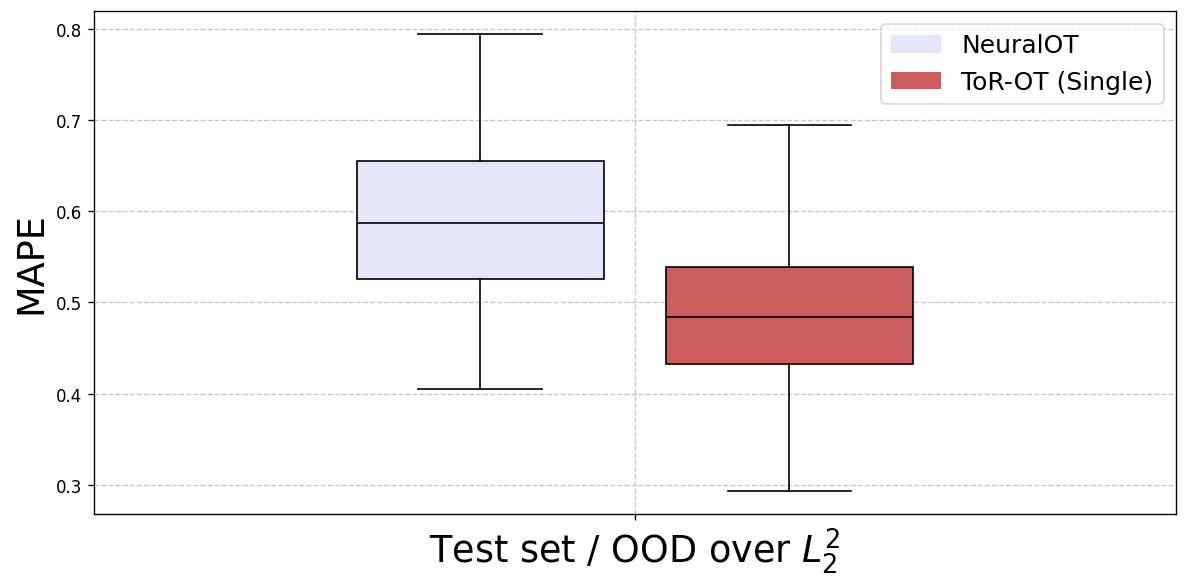

Generating Test Set Plot for Hellinger...


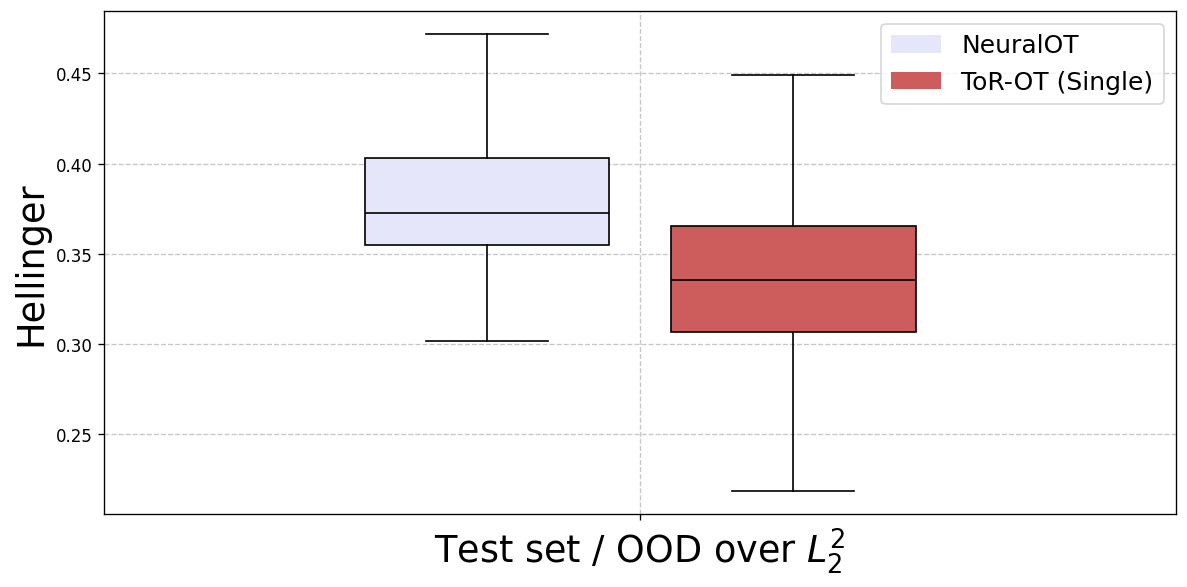

Generating Test Set Plot for OT Cost Diff...


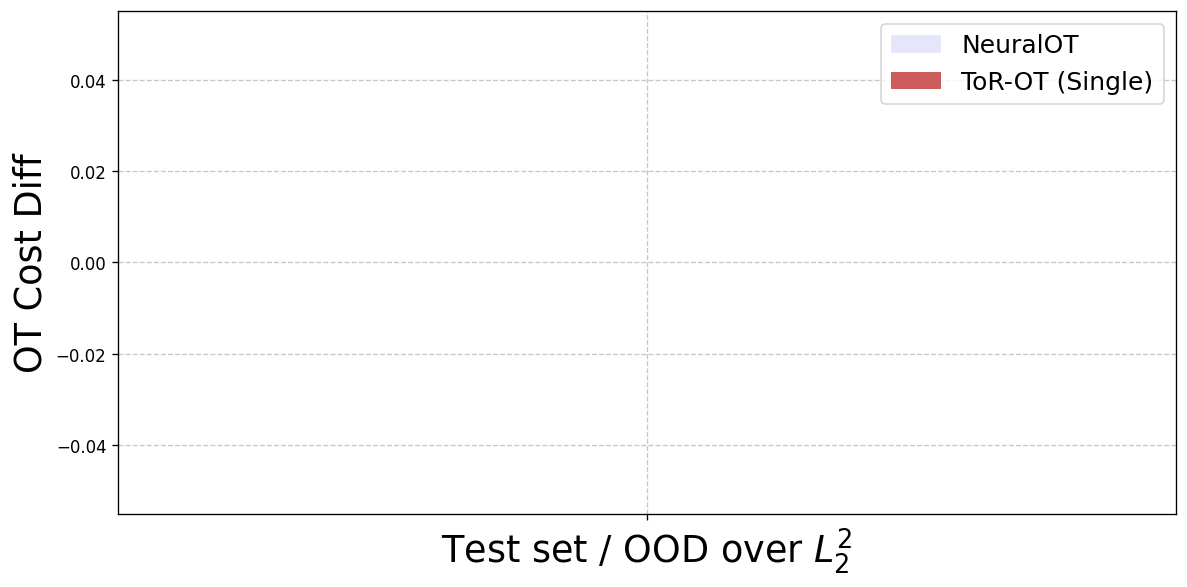

Generating Test Set Plot for Total Variation...


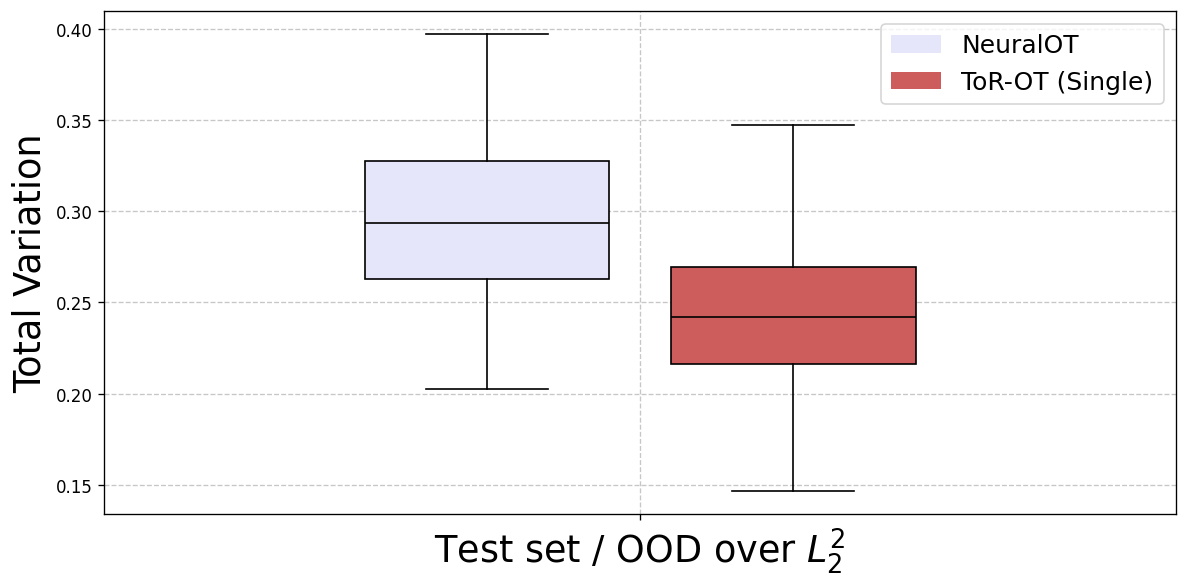

Generating Test Set Plot for Run Time (Seconds)...
Saved: img/2d_testset_run_time_seconds.png


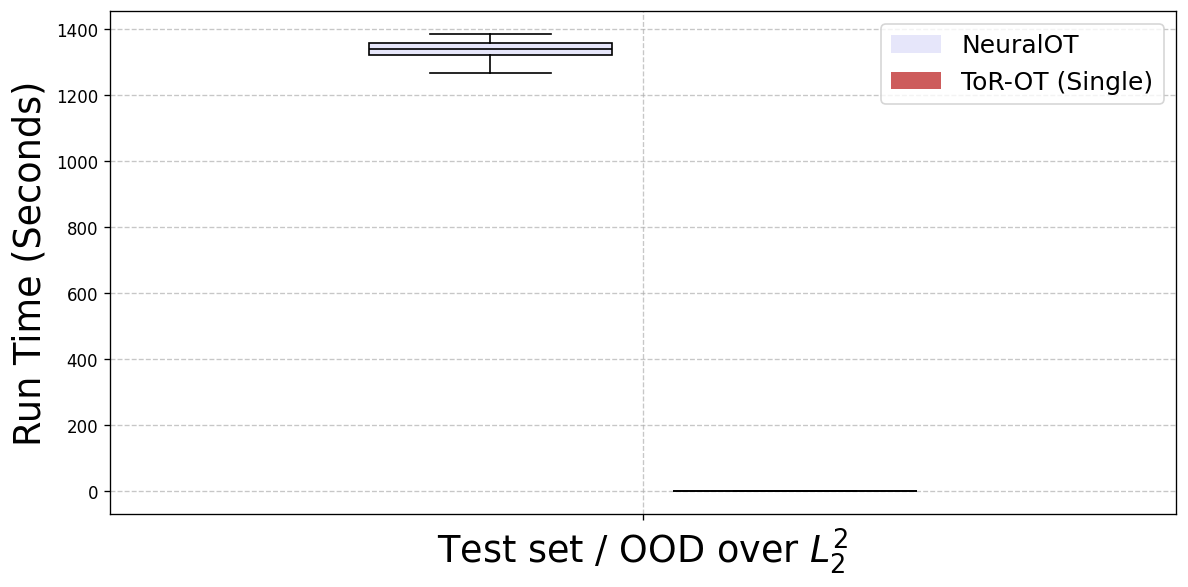

In [5]:
print("="*80)
print("TEST SET ANALYSIS")
print("="*80)

# Model directory templates
MODEL_INDIV_TEMPLATE = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data100K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch192_{}"
MODEL_JOINT_NAME     = "model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean"
PERFORMANCE_METRICS = ['MAE', 'MAPE', 'Hellinger', 'OT Cost Diff', 'Total Variation', 'Run Time (Seconds)']


# 1. Define Helper to Load Data
def load_testset_npz(path):
    if not os.path.exists(path):
        print(f"Path does not exist: {path}")
        return None
    try:
        print("Loading: ", path)
        data = np.load(path, allow_pickle=True)
        # print some of its content
        print("Data: ", data[0])
        print("Data type: ", type(data))
        print("Data[0] type: ", type(data[0]))
        print("Data shape: ", data.shape)
        # Map npz keys to display keys. 
        # NPZ keys: 'mae', 'mape', 'hellinger', 'otcost_diff', 'tv'
        ret = {}
        ret['MAE'] = np.array([d['mae_sparse'] for d in data])
        ret['MAPE'] = np.array([d['mape_sparse'] for d in data])
        ret['Hellinger'] = np.array([d['hellinger_sparse'] for d in data])
        ret['Total Variation'] = np.array([d['tv_sparse'] for d in data])
        ret['Run Time (Seconds)'] = np.array([d['run_time'] for d in data])
        print("Loaded: ", ret)
        return ret
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

# 2. Pre-load ALL Test Set Data
all_testset_data = {}

# Define Keys for plotting order and retrieval
# User requested keys: NOT_INDIV, TOT_INDIV, TOT_JOINT (Reordered)
TESTSET_KEYS = ['NOT_INDIV', 'TOT_INDIV']#, 'TOT_JOINT']

# Map keys to paths/loading logic
for metric in METRICS:
    print("Trying metric: ", metric)
    all_testset_data[metric] = {}
    
    # INDIV Paths (Updated to include metric in filename)
    dir_indiv = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_INDIV_TEMPLATE.format(metric))
    
    # User requested specific paths:
    # path_indiv_tot = ... f"eval_all_testset_1d_{metric}_results_tot.npz"
    # path_indiv_not = ... f"eval_all_testset_1d_{metric}_results_not.npz"
    # Note: run_inference.py saves .npz, so we use .npz
    
    path_tot_indiv = os.path.join(dir_indiv, f"eval_all_testset_2d_{metric}_results_tot.npy")
    path_not_indiv = os.path.join(dir_indiv, f"eval_all_testset_2d_{metric}_results_not.npy")

    # JOINT Paths
    dir_joint = os.path.join(EXPERIMENT_DIR_INDIV, MODEL_JOINT_NAME)
    path_tot_joint = os.path.join(dir_joint, f"eval_all_testset_2d_{metric}_results_tot.npy")
    # path_not_joint = os.path.join(dir_joint, f"eval_all_testset_1d_results_not_{metric}.npz") # Excluded
    
    # Load and populate
    val = load_testset_npz(path_tot_indiv)
    if val: all_testset_data[metric]['TOT_INDIV'] = val
    # print some results for testing
    print("TOT_INDIV: ", val)
        
    val = load_testset_npz(path_not_indiv)
    if val: all_testset_data[metric]['NOT_INDIV'] = val
    print("NOT_INDIV: ", val)

    # OOD Loading
    # Assume OOD files follow: eval_all_ood_2d_{metric}_results_{model}.npy
    path_tot_ood = os.path.join(dir_joint, f"eval_all_testset_2d_{metric}_results_tot.npy")
    path_not_ood = os.path.join(dir_indiv, f"eval_all_testset_2d_{metric}_results_not.npy")
    
    val = load_testset_npz(path_tot_ood)
    if val: all_testset_data[metric]['TOT_OOD'] = val
    else: print(f"  No OOD TOT data found for {metric} at {path_tot_ood}")

    val = load_testset_npz(path_not_ood)
    if val: all_testset_data[metric]['NOT_OOD'] = val
    else: print(f"  No OOD NOT data found for {metric} at {path_not_ood}")

        
    #val = load_testset_npz(path_tot_joint)
    #if val: all_testset_data[metric]['TOT_JOINT'] = val
    #print("TOT_JOINT: ", val)

# display some results for testing, format the dict to be more readable
print("All Test Set Data:")
for metric, data in all_testset_data.items():
    print(f"Metric: {metric}")
    for key, values in data.items():
        print(f"  {key}: {values}")


# 3. Generate Plots (One per Performance Metric)
# Colors matching the keys: IndianRed (NOT), Lavender (TOT), LightGreen (TOT_JOINT)
# Reordered matches TESTSET_KEYS: ['NOT_INDIV', 'TOT_INDIV', 'TOT_JOINT']
TESTSET_COLORS = ['lavender', 'indianred', 'lightgreen']

for perf_metric in PERFORMANCE_METRICS:
    print(f"Generating Test Set Plot for {perf_metric}...")
    
    plot_data = []
    valid_dist_metrics = [] # Distance metrics that have data
    
    # Collect data across all distance metrics
    for dist_metric in METRICS:
        if dist_metric not in all_testset_data:
            continue
            
        # Check if we have ANY data for this distance metric
        if not all_testset_data[dist_metric]:
            continue
            
        # We found some data, so this X-axis point is valid
        valid_dist_metrics.append(dist_metric)
        
        # Append data for each Model Key in order
        for key in TESTSET_KEYS:
            model_data = all_testset_data[dist_metric].get(key, {})
            # extract_metrics was used before, but here we load npz directly which returns dict of arrays
            values = model_data.get(perf_metric, [])
            
            # Clean NaNs
            if isinstance(values, np.ndarray):
                values = values[~np.isnan(values)] if len(values) > 0 else []
            elif isinstance(values, list):
                 values = [v for v in values if v is not None]
                 
            plot_data.append(values)

    if not plot_data:
        print(f"No data found for {perf_metric}")
        continue

    # Setup Plot
    fig, ax = plt.subplots(figsize=(10, 5), dpi=120)

    # Position calculations
    num_distance_metrics = len(valid_dist_metrics)
    num_bars_per_group = len(TESTSET_KEYS)
    group_width = 0.8
    bar_width = group_width / num_bars_per_group

    positions = []
    for i in range(num_distance_metrics):
        center = i + 1
        start_offset = -(num_bars_per_group - 1) * bar_width / 2.0
        for j in range(num_bars_per_group):
            offset = start_offset + (j * bar_width)
            positions.append(center + offset)

    # Boxplot
    bp = ax.boxplot(plot_data, positions=positions, widths=bar_width*0.8, 
                    patch_artist=True, medianprops=dict(color="black"), showfliers=False)

    # Color values
    for i, patch in enumerate(bp['boxes']):
        color_idx = i % num_bars_per_group
        patch.set_facecolor(TESTSET_COLORS[color_idx])

    # X-axis Labels
    ax.set_xticks(range(1, num_distance_metrics + 1))
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_dist_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)

    # Title and Grid
    #ax.set_title(f'Test Set comparison: {perf_metric} across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=TESTSET_COLORS[i], label=LABEL_MAPPING.get(TESTSET_KEYS[i], TESTSET_KEYS[i]))
        for i in range(len(TESTSET_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=15)

    plt.tight_layout()
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/2d_testset_{safe_metric}.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    
    plt.show()
# OOD Keys
OOD_KEYS = ['NOT_OOD', 'TOT_OOD']

Generating OOD Comparison Plot for MAE...


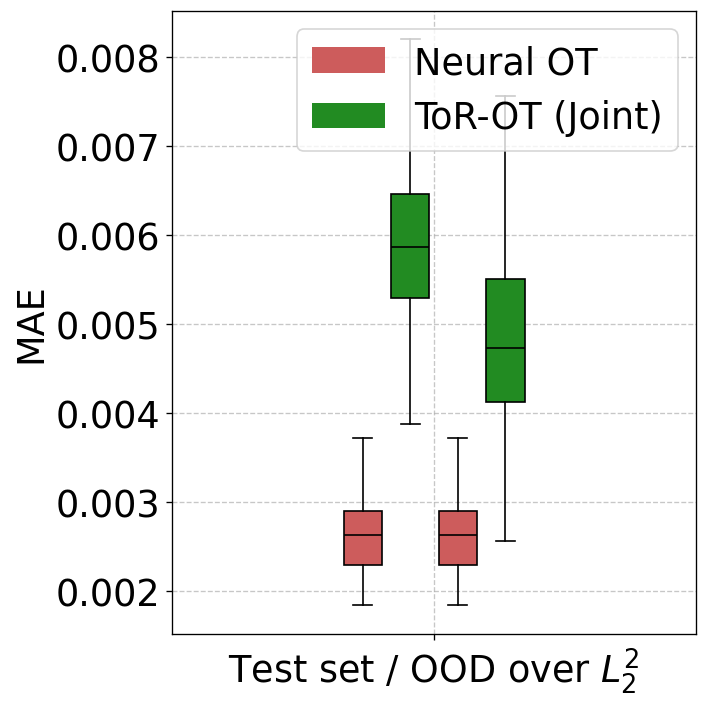

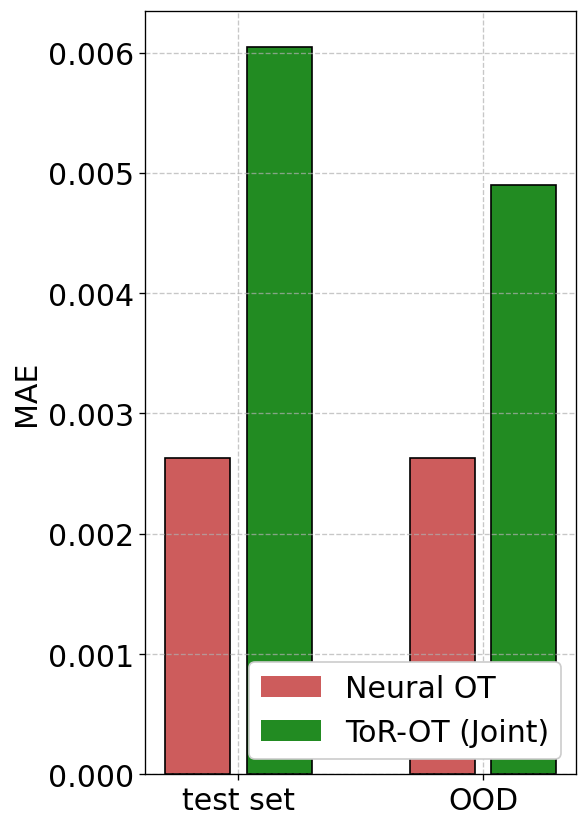

Generating OOD Comparison Plot for MAPE...
Saved: img/2d_ood_mape.png


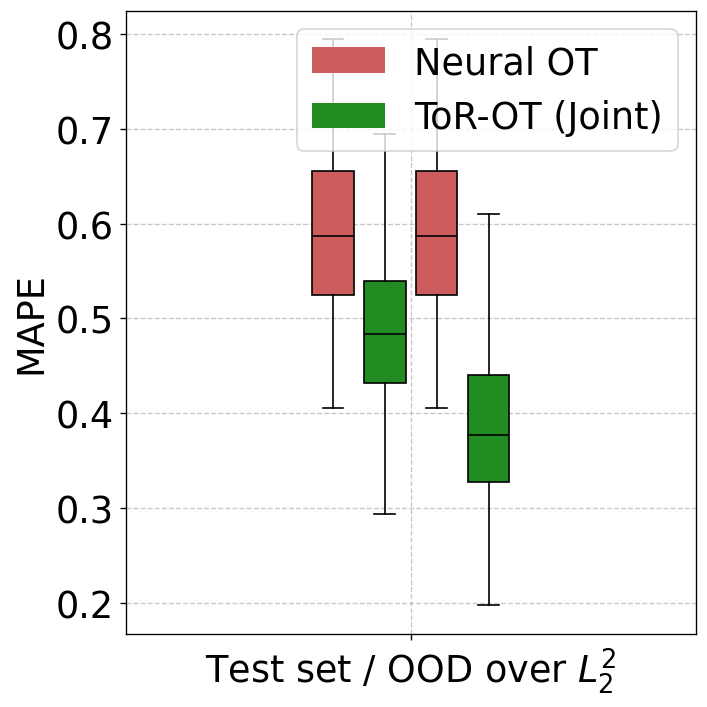

Saved: img/2d_ood_mape_bar.png


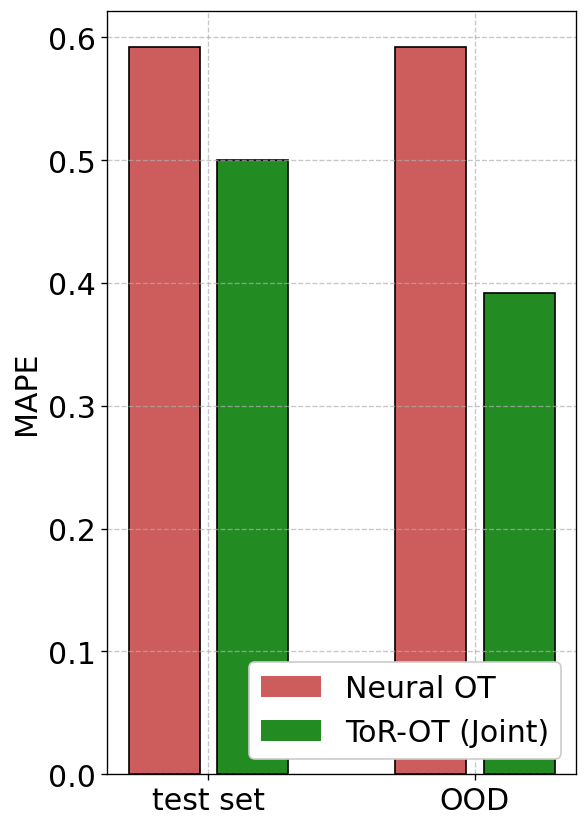

Generating OOD Comparison Plot for Hellinger...


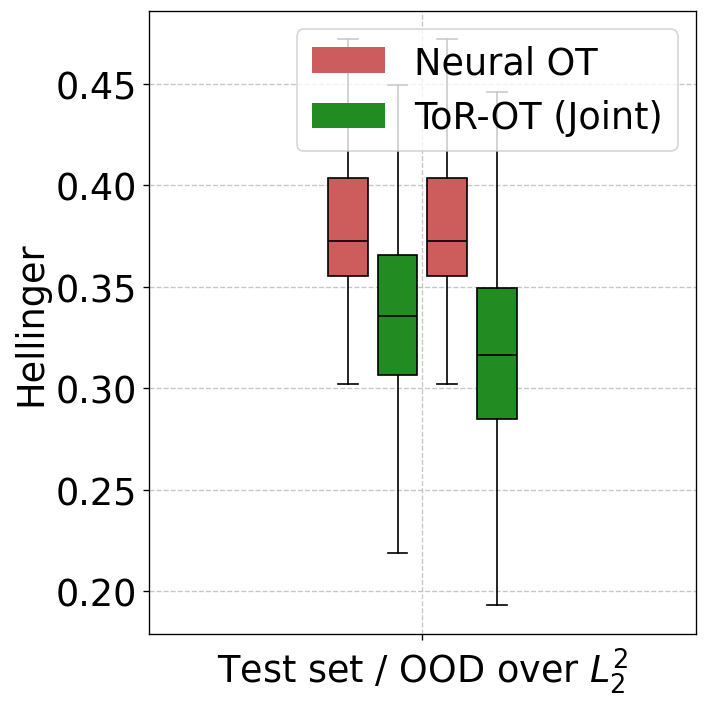

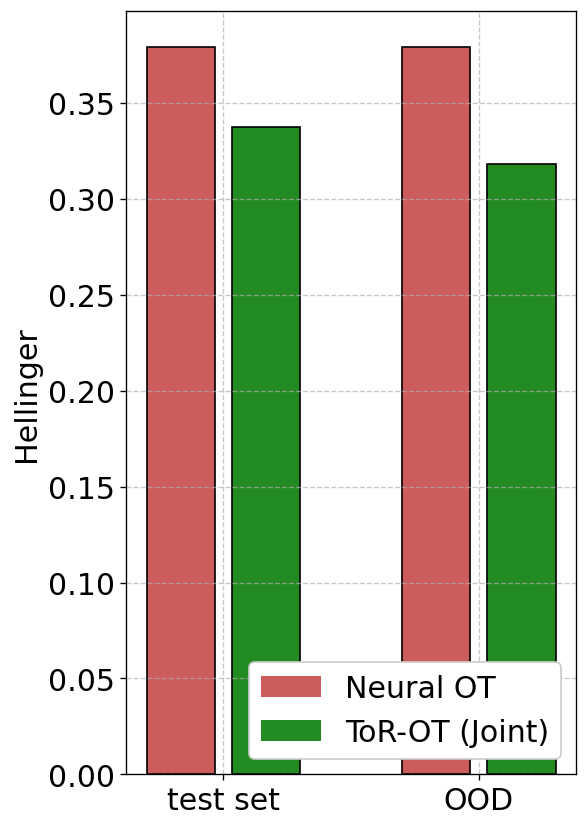

Generating OOD Comparison Plot for OT Cost Diff...
No valid data found for OT Cost Diff (OOD Comparison)
Generating OOD Comparison Plot for Total Variation...


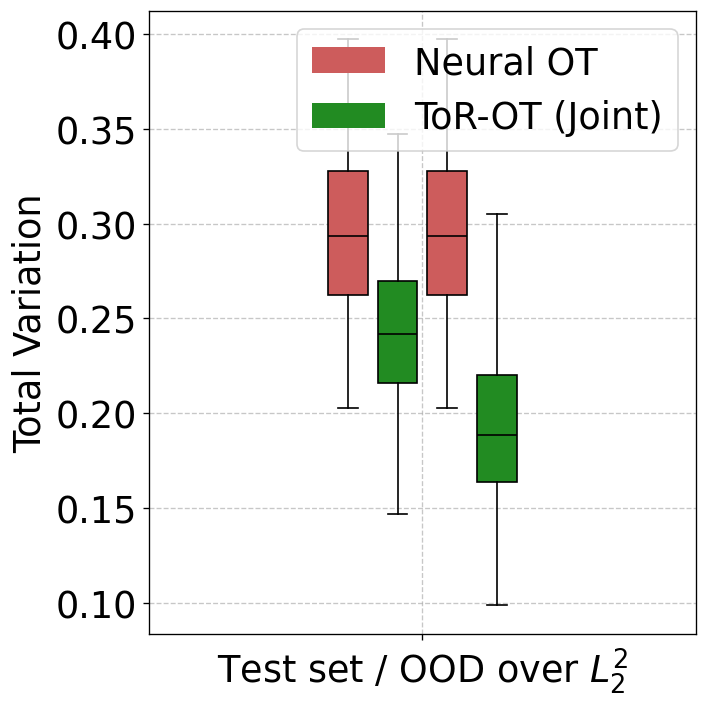

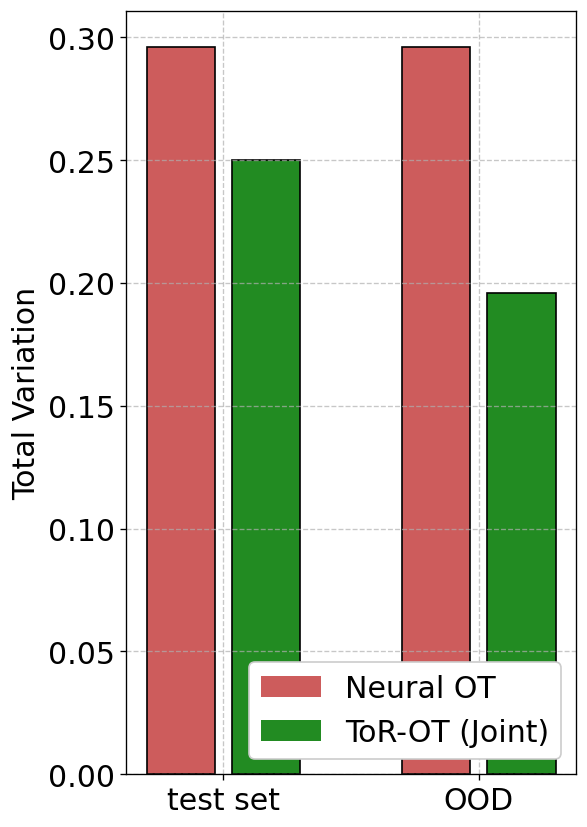

Generating OOD Comparison Plot for Run Time (Seconds)...


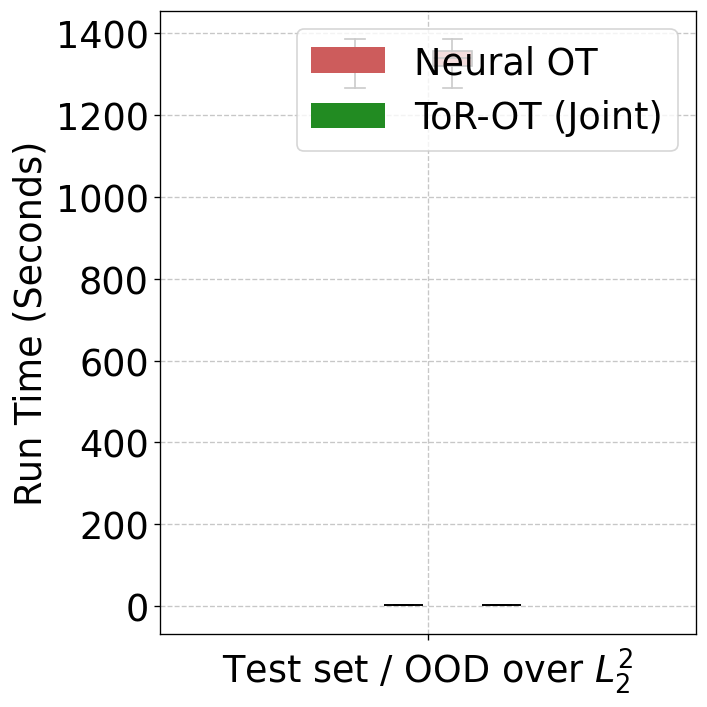

Saved: img/2d_ood_run_time_seconds_bar.png


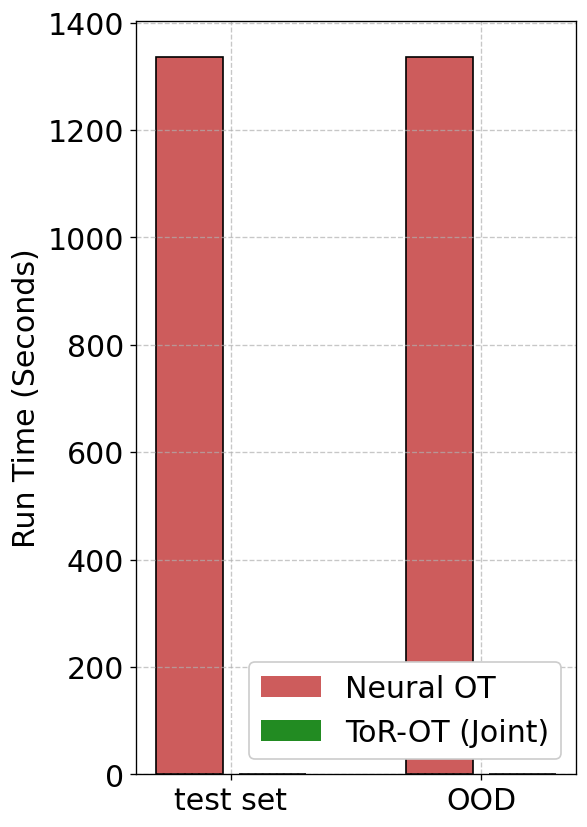

In [6]:

# OOD vs Test Set Comparison Boxplots
# Comparing: Testset (NOT, TOT) vs OOD (NOT, TOT)

PLOT_KEYS = ['NOT_INDIV', 'TOT_INDIV', 'NOT_OOD', 'TOT_OOD']
PLOT_COLORS = 2*['indianred', 'forestgreen'] # Red, Green, Orange, Blue-ish
PLOT_LABELS = ['Neural OT', 'ToR-OT (Joint)', 'Neural OT',  'ToR-OT (Joint)']

for perf_metric in PERFORMANCE_METRICS:
    print(f"Generating OOD Comparison Plot for {perf_metric}...")
    
    plot_data = []
    valid_dist_metrics = [] 
    
    for dist_metric in METRICS:
        if dist_metric not in all_testset_data: continue
        if not all_testset_data[dist_metric]: continue
            
        # Check if we have OOD data specifically to make the plot meaningful?
        # Or just plot what we have (NaNs for missing)
        
        valid_dist_metrics.append(dist_metric)
        
        for key in PLOT_KEYS:
            model_data = all_testset_data[dist_metric].get(key, {})
            values = model_data.get(perf_metric, [])
            
            if isinstance(values, np.ndarray):
                values = values[~np.isnan(values)] if len(values) > 0 else []
            elif isinstance(values, list):
                 values = [v for v in values if v is not None]
                 
            plot_data.append(values)

    if not plot_data or all(len(x)==0 for x in plot_data):
        print(f"No valid data found for {perf_metric} (OOD Comparison)")
        continue

    # Setup Plot
    fig, ax = plt.subplots(figsize=(6, 6), dpi=120)

    num_groups = len(valid_dist_metrics)
    num_bars = len(PLOT_KEYS)
    group_width = 0.5
    bar_width = group_width / num_bars

    positions = []
    for i in range(num_groups):
        center = i + 1
        start_offset = -(num_bars - 1) * bar_width / 2.0
        for j in range(num_bars):
            offset = start_offset + (j * bar_width)
            positions.append(center + offset)

    # Boxplot
    bp = ax.boxplot(plot_data, positions=positions, widths=bar_width*0.8, 
                    patch_artist=True, medianprops=dict(color="black"), showfliers=False)

    # Colors
    for i, patch in enumerate(bp['boxes']):
        color_idx = i % num_bars
        patch.set_facecolor(PLOT_COLORS[color_idx])

    # X Actions
    ax.set_xticks(range(1, num_groups + 1))
    xtick_labels = [METRIC_LABELS.get(m, m) for m in valid_dist_metrics]
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=22)
    ax.tick_params(axis='y', labelsize=22)
    ax.set_ylabel(perf_metric, fontsize=22)
    ax.grid(True, linestyle='--', alpha=0.7)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=PLOT_COLORS[i], label=PLOT_LABELS[i])
        for i in range(len(PLOT_KEYS)-2)
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=22)
    plt.tight_layout()
    
    if perf_metric in ['MAPE']:
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/2d_ood_{safe_metric}.png"
        os.makedirs(os.path.dirname(out_png), exist_ok=True)
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
        
    plt.show()



    fig, ax = plt.subplots(figsize=(5, 7), dpi=120)

    plot_data_np = np.array([np.mean(plot_data[i]) for i in range(len(plot_data))])
    bp = ax.bar([0, 1, 3, 4], plot_data_np, width=0.8, facecolor=PLOT_COLORS, edgecolor='black')

    # Set X-axis labels
    ax.set_xticks([0.5, 3.5])
    # Use mapped labels for X-axis
    xtick_labels = ['test set', 'OOD']
    ax.set_xticklabels(xtick_labels, rotation=0, ha='center', fontsize=18)
    
    ax.tick_params(axis='y', labelsize=18)

    #ax.set_title(f'OOD comparison: {perf_metric} across cost types', fontsize=24)
    #ax.set_title(f'Run Time across cost types', fontsize=24)
    ax.set_ylabel(perf_metric, fontsize=18)
    ax.grid(True, linestyle='--', alpha=0.7)
    
    # Custom Legend using Mapped Labels
    from matplotlib.patches import Patch
    # Use DATA_KEYS order to get colors and map to labels
    legend_elements = [
        Patch(facecolor=PLOT_COLORS[i], label=PLOT_LABELS[i]) 
        for i in range(len(DATA_KEYS))
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=18, ncols=1, framealpha=1)
    
    plt.tight_layout()
    # Save only selected metrics
    if perf_metric in ['MAPE', 'Run Time (Seconds)']:
        # make a filesystem-safe name like: testset_mape.png, testset_run_time_seconds.png
        safe_metric = re.sub(r'[^a-z0-9]+', '_', perf_metric.lower()).strip('_')
        out_png = f"img/2d_ood_{safe_metric}_bar.png"
        plt.savefig(out_png, bbox_inches='tight', dpi=300)
        print(f"Saved: {out_png}")
    plt.show()


# Joint Model vs Neural OT Comparison (Heatmap)

This section compares the 'sqeuclidean' OT Cost Difference between the Joint Model (TOT) and Neural OT (NOT). The heatmap shows the percentage of improvement of the Joint Model over Neural OT.

Loading TOT data from: ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_tot.npy
Loading NOT data from: ../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_not.npy
Matrix Dimensions: 7x7


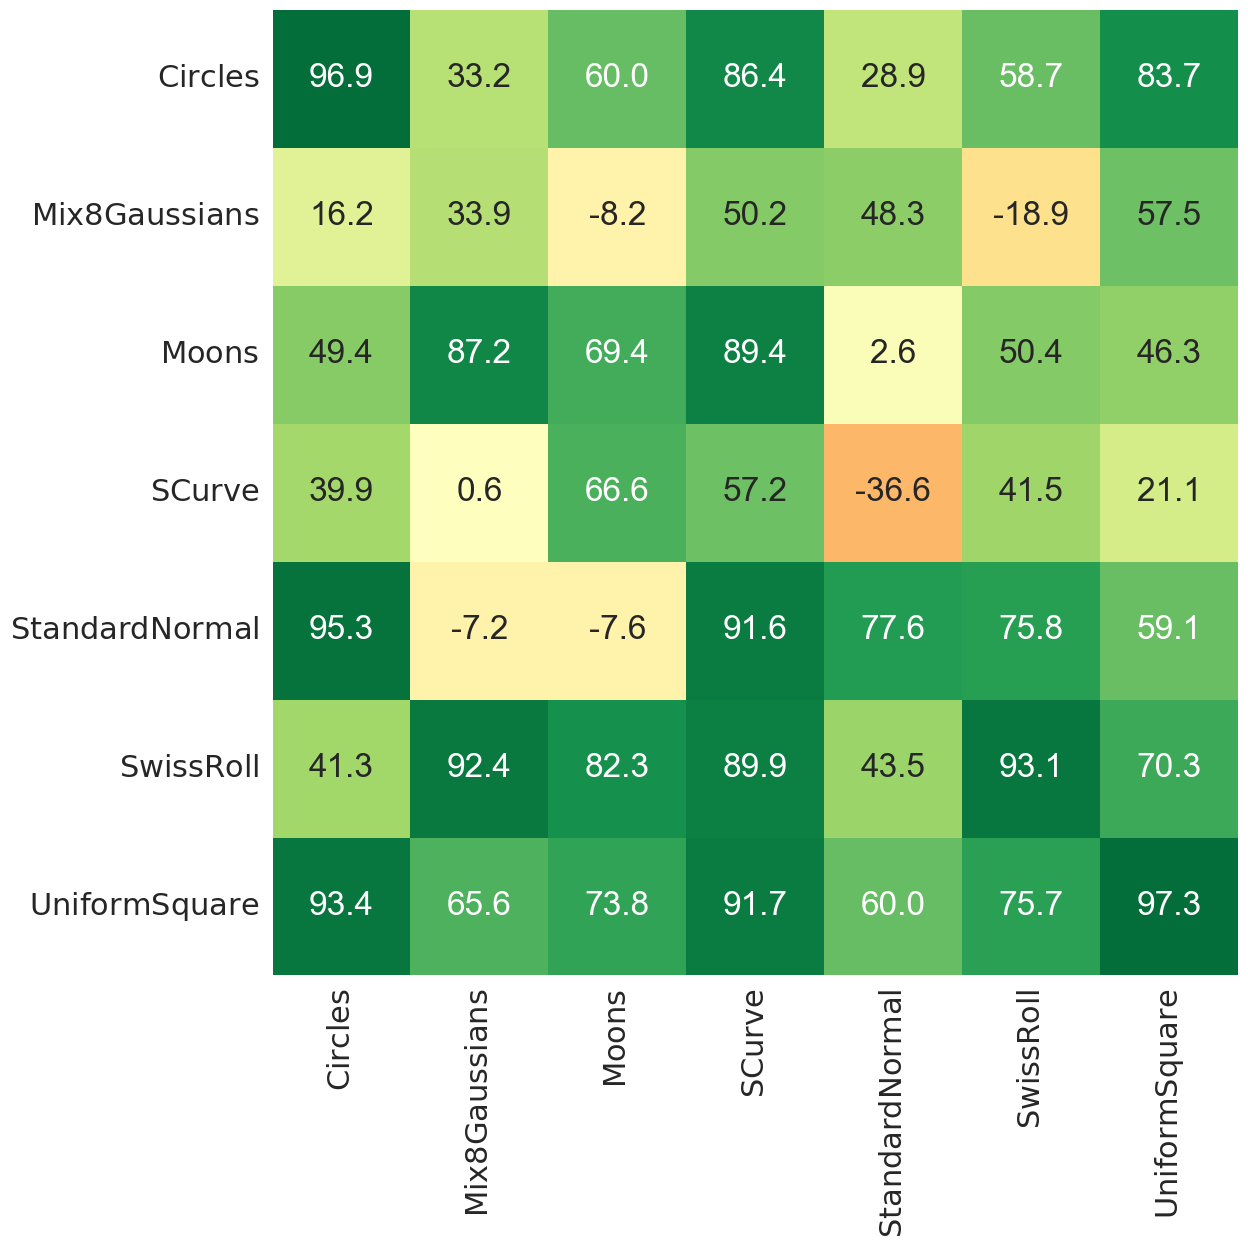

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Result File Paths
#joint
#path_tot_sq = "/home/ivan/repos/TF4OT/experiments/cost_semivariable/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data600K_rowwise_costsemivariable_prec4_bins30_DigitTokenizer_epochs25_batch128/eval_all_pairs_1d_sqeuclidean_results_tot.npy"
#individual
path_tot_sq = "../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_tot.npy"
#not
path_not_sq = "../../../experiments/cost_fixed/model_dim768_context512_tflayers24_tfheads16_num_prefix1_dropout0_flashTrue_data500K_rowwise_costfixed_prec4_bins36_DigitTokenizer_epochs50_batch256_sqeuclidean/eval_all_pairs_2d_sqeuclidean_results_not.npy"

# Load Data
print(f"Loading TOT data from: {path_tot_sq}")
data_tot = np.load(path_tot_sq, allow_pickle=True)
print(f"Loading NOT data from: {path_not_sq}")
data_not = np.load(path_not_sq, allow_pickle=True)

# -----------------------------
# LaTeX labels for distributions
# (must match TorchSampler .name strings)
# -----------------------------
DIST_TEX = {
    # Beta is on [0,1]
    "BetaLeft":        r'$\mathrm{Beta_L}(2,5)$',
    "BetaRight":       r'$\mathrm{Beta_R}(5,2)$',

    "Laplace":         r'$\mathrm{Lap}(0,1)$',
    "Uniform":         r'$\mathrm{Unif}(-2,2)$',

    "StudentT":        r'$t_{\nu=5}$',
    "GaussianShifted": r'$\mathcal{N}_{\mathrm{shift}}(\mu=1.0,\sigma=1.0)$',

    "LogNormal":       r'$\mathrm{LogN}(\mu=0,\sigma=0.6)$',
    "CauchyTrunc":     r'$\mathrm{Cauchy}(\gamma=1;\,|x|\leq 5)$',

    "Triangular":      r'$\mathrm{Tri}(-3,0,3)$',
    "Exponential":     r'$\mathrm{Exp}(\mathrm{scale}=1)$',
    "Weibull":         r'$\mathrm{Wei}(a=2,\mathrm{scale}=1)$',
    "Gamma":           r'$\Gamma(\alpha=2,\mathrm{scale}=1)$',
}

def tex(name: str) -> str:
    # fallback (escape underscores if any)
    safe = str(name).replace('_', r'\_')
    return DIST_TEX.get(name, rf'$\mathrm{{{safe}}}$')

# Extract Unique Distributions
sources = sorted(list(set([item['source'] for item in data_tot])))
targets = sorted(list(set([item['target'] for item in data_tot])))
    # --------------------------------
    # Exclude specific distributions
    # --------------------------------
#EXCLUDE_DISTS = {"Laplace", "GaussianShifted", "LogNormal"}
#sources = [s for s in sources if s not in EXCLUDE_DISTS]
#targets = [t for t in targets if t not in EXCLUDE_DISTS]
    
n_sources = len(sources)
n_targets = len(targets)

print(f"Matrix Dimensions: {n_sources}x{n_targets}")

# Initialize Matrix
improvement_matrix = np.zeros((n_sources, n_targets))

# Map data
def find_item(data, s, t):
    for item in data:
        if item['source'] == s and item['target'] == t:
            return item
    return None

eps = 1e-12
for i, s in enumerate(sources):
    for j, t in enumerate(targets):
        item_tot = find_item(data_tot, s, t)
        item_not = find_item(data_not, s, t)

        if item_tot is not None and item_not is not None:
            val_tot = item_tot['mape_sparse']
            val_not = item_not['mape_sparse']

            # % improvement (percent reduction) of TOT over baseline NOT
            improvement_pct = 100.0 * (val_not - val_tot) / max(val_not, eps)
            improvement_matrix[i, j] = improvement_pct
        else:
            improvement_matrix[i, j] = np.nan

# -----------------------------
# Plot Heatmap with LaTeX tick labels
# -----------------------------
plt.style.use("default")  # avoid seaborn-style gray backgrounds
plt.figure(figsize=(13, 13))
sns.set(font_scale=2)

xlabels = [tex(t) for t in targets]
ylabels = [tex(s) for s in sources]

ax = sns.heatmap(
    improvement_matrix,
    annot=True, fmt=".1f",
    xticklabels=xlabels,
    yticklabels=ylabels,
    cmap="RdYlGn",
    center=0,
    cbar=False,
    vmin=-100,
    vmax=100
)

# plt.title(r'$\%$ improvement of ToR-OT (Single) over Neural OT', fontsize=22)
# plt.xlabel("Target Distribution", fontsize=22)
# plt.ylabel("Source Distribution", fontsize=22)
plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



Generating Amortized Runtime Plot


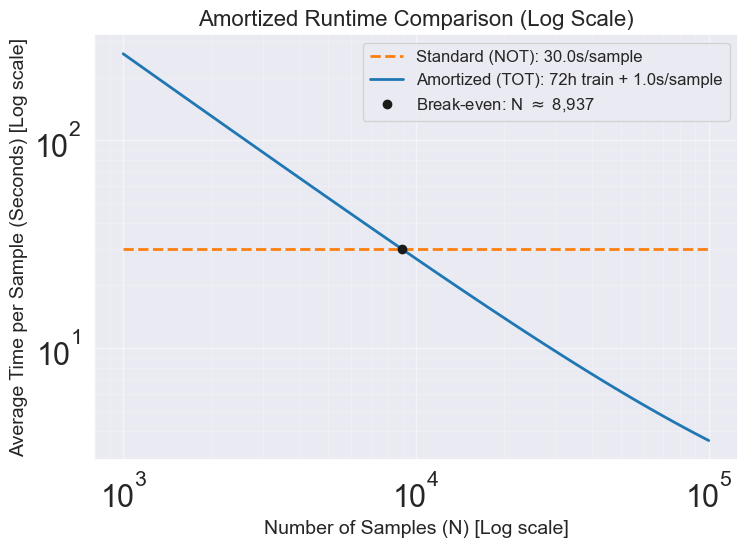

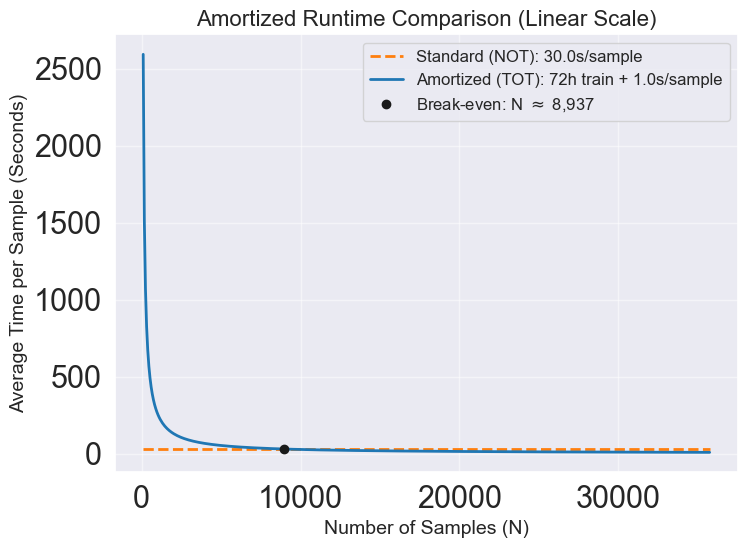

In [8]:

# -----------------------------
# Amortized Runtime Comparison
# -----------------------------
print(f"\n{'='*40}\nGenerating Amortized Runtime Plot\n{'='*40}")

T_TRAIN_HOURS = 72
T_TRAIN_SEC = T_TRAIN_HOURS * 3600

# User specified T_infer=1s for amortized method (TOT)
T_TOT_INFER_SEC = 1.0 

# Estimated runtime for Neural OT (NOT) based on max_steps=2501 in toy code.
# Assuming ~10-15ms per step => ~30 seconds per sample.
T_NOT_SEC = 30.0 

# Determine break-even N
# T_TRAIN/N + T_TOT_INFER = T_NOT
if T_NOT_SEC > T_TOT_INFER_SEC:
    N_break_even = T_TRAIN_SEC / (T_NOT_SEC - T_TOT_INFER_SEC)
else:
    N_break_even = 1e6 # Fallback

# --- Plot 1: Log Scale ---
min_exp = 3  # 10^3
max_exp = int(np.log10(N_break_even)) + 2 
N_values_log = np.logspace(min_exp, max_exp, 100)

avg_time_tot_log = (T_TRAIN_SEC / N_values_log) + T_TOT_INFER_SEC
avg_time_not_log = np.full_like(N_values_log, T_NOT_SEC)

plt.figure(figsize=(8, 6))
plt.loglog(N_values_log, avg_time_not_log, label=f'Standard (NOT): {T_NOT_SEC}s/sample', linewidth=2, color='tab:orange', linestyle='--')
plt.loglog(N_values_log, avg_time_tot_log, label=f'Amortized (TOT): {T_TRAIN_HOURS}h train + {T_TOT_INFER_SEC}s/sample', linewidth=2, color='tab:blue')
plt.plot(N_break_even, T_NOT_SEC, 'ko', label=f'Break-even: N $\\approx$ {int(N_break_even):,}')

plt.xlabel('Number of Samples (N) [Log scale]', fontsize=14)
plt.ylabel('Average Time per Sample (Seconds) [Log scale]', fontsize=14)
plt.title('Amortized Runtime Comparison (Log Scale)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.grid(True, which="major", ls="-", alpha=0.5)
plt.tight_layout()
plt.show()


# --- Plot 2: Linear Scale ---
max_N = int(N_break_even * 4) 
N_values_lin = np.linspace(100, max_N, 500)

avg_time_tot_lin = (T_TRAIN_SEC / N_values_lin) + T_TOT_INFER_SEC
avg_time_not_lin = np.full_like(N_values_lin, T_NOT_SEC)

plt.figure(figsize=(8, 6))
plt.plot(N_values_lin, avg_time_not_lin, label=f'Standard (NOT): {T_NOT_SEC}s/sample', linewidth=2, color='tab:orange', linestyle='--')
plt.plot(N_values_lin, avg_time_tot_lin, label=f'Amortized (TOT): {T_TRAIN_HOURS}h train + {T_TOT_INFER_SEC}s/sample', linewidth=2, color='tab:blue')
plt.plot(N_break_even, T_NOT_SEC, 'ko', label=f'Break-even: N $\\approx$ {int(N_break_even):,}')

plt.xlabel('Number of Samples (N)', fontsize=14)
plt.ylabel('Average Time per Sample (Seconds)', fontsize=14)
plt.title('Amortized Runtime Comparison (Linear Scale)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.2)
plt.grid(True, which="major", ls="-", alpha=0.5)
plt.tight_layout()
plt.show()
